# Module 15 — Exercises — Solutions

Exercises for **Module 15 — Generalisation and Statistical Learning Theory**. They follow the
order of the [concept guide](README.md): Hoeffding sample sizes, Chebyshev versus Hoeffding,
the finite-class bound, growth functions and VC dimension by brute force, the optimism of
selecting the best of many models, gradient descent versus the pseudo-inverse, a double-descent
experiment, two conceptual questions, and a mini-project that fits a power law to the
generalisation gap. Use only NumPy and the standard library (plus `scipy` where a prompt says
so) and keep everything seeded.

This notebook contains reference solutions and explanations for every exercise. Try the exercises yourself first — the learning happens in the struggle.

### Setup and self-check helpers
Run the next two cells first.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb, log, sqrt, exp
rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (7, 4)
np.set_printoptions(precision=4, suppress=True)

In [2]:
import hashlib as _hashlib
import numpy as _np

_results = {}

def _canon(value, decimals=3):
    """Canonical string form of an answer, so hashes are stable."""
    if isinstance(value, (bool, _np.bool_)):
        return "true" if value else "false"
    if isinstance(value, str):
        return " ".join(value.strip().lower().split())
    if isinstance(value, (int, _np.integer)):
        return str(int(value))
    if isinstance(value, (float, _np.floating)):
        s = f"{float(value):.{decimals}f}"
        return "0." + "0" * decimals if s in ("-0." + "0" * decimals, "-0") else s
    if isinstance(value, dict):
        return "{" + ",".join(f"{_canon(k, decimals)}:{_canon(v, decimals)}" for k, v in sorted(value.items(), key=lambda kv: str(kv[0]))) + "}"
    try:
        arr = _np.asarray(value)
        if arr.ndim == 0:
            return _canon(arr.item(), decimals)
        return "[" + ",".join(_canon(x, decimals) for x in arr.ravel().tolist()) + "]"
    except Exception:
        return str(value)

def sha_of(value, decimals=3):
    return _hashlib.sha256(_canon(value, decimals).encode()).hexdigest()[:16]

def check(name, condition, hint=""):
    """Record and print a pass/fail mark. Never raises, so the notebook keeps running."""
    try:
        ok = bool(condition)
    except Exception:
        ok = False
    _results[name] = ok
    print(("✅ " if ok else "❌ ") + name + ("" if ok or not hint else f"   — hint: {hint}"))
    return ok

def check_close(name, got, expected, tol=1e-6, hint=""):
    try:
        g = _np.asarray(got, dtype=float)
        e = _np.asarray(expected, dtype=float)
        ok = g.shape == e.shape and bool(_np.allclose(g, e, atol=tol, rtol=tol))
    except Exception:
        ok = False
    return check(name, ok, hint)

def check_hash(name, value, expected_sha, decimals=3, hint=""):
    """Compare an answer against a hidden expected value (only its hash is stored)."""
    try:
        ok = value is not None and sha_of(value, decimals) == expected_sha
    except Exception:
        ok = False
    return check(name, ok, hint)

def summary():
    n_ok = sum(1 for v in _results.values() if v)
    n = len(_results)
    print(f"\nScore: {n_ok}/{n} checks passed" + ("  🎉" if n and n_ok == n else ""))
    if n and n_ok < n:
        print("Not yet passing: " + ", ".join(k for k, v in _results.items() if not v))

## Exercise 1 — Hoeffding sample size and deviation  `★☆☆`

For a *fixed* classifier evaluated on $n$ i.i.d. test examples, Hoeffding's inequality gives,
with probability at least $1 - \delta$, $|\hat a - a| \le \sqrt{\ln(2/\delta)/(2n)}$.

Implement

* `hoeffding_n(eps, delta)` — the smallest **integer** $n$ (use `np.ceil`, return a Python `int`)
  guaranteeing $|\hat a - a| \le \varepsilon$ with probability $\ge 1-\delta$;
* `hoeffding_eps(n, delta)` — the deviation $\varepsilon$ guaranteed by $n$ examples (a `float`).

Then set `n_benchmark = hoeffding_n(0.01, 0.01)` (a benchmark that pins accuracy to one point
at 99 %) and `eps_benchmark = hoeffding_eps(5000, 0.05)`.

In [3]:
def hoeffding_n(eps, delta):
    return int(np.ceil(np.log(2.0 / delta) / (2.0 * eps ** 2)))

def hoeffding_eps(n, delta):
    return float(np.sqrt(np.log(2.0 / delta) / (2.0 * n)))

n_benchmark = hoeffding_n(0.01, 0.01)
eps_benchmark = hoeffding_eps(5000, 0.05)

**Check your answer:**

In [4]:
try:
    got_n = hoeffding_n(0.02, 0.05)
except Exception:
    got_n = None
check('n for eps = 0.02, delta = 0.05 is 4612', got_n == 4612, hint="ln(40) / (2 * 0.0004), rounded up")
try:
    got_eps = hoeffding_eps(4612, 0.05)
except Exception:
    got_eps = None
check('eps for n = 4612, delta = 0.05 is just under 0.02', got_eps is not None and 0.0199 < got_eps <= 0.02)
check_hash('hidden: n_benchmark', n_benchmark if isinstance(n_benchmark, (int, np.integer)) else None, '68206c4949fc2c4e')
check_hash('hidden: eps_benchmark (3 decimals)', eps_benchmark if isinstance(eps_benchmark, float) else None, 'b654f6a8a45bb365')

✅ n for eps = 0.02, delta = 0.05 is 4612
✅ eps for n = 4612, delta = 0.05 is just under 0.02
✅ hidden: n_benchmark
✅ hidden: eps_benchmark (3 decimals)


True

**Why this works**

Set $2e^{-2n\varepsilon^2} = \delta$ and solve: $n = \ln(2/\delta)/(2\varepsilon^2)$, rounded *up* because
$n$ must be an integer and the inequality must still hold. The deviation form is the same
equation solved for $\varepsilon$. Note the asymmetry: halving $\varepsilon$ quadruples $n$, while
cutting $\delta$ from 0.05 to 0.01 only raises $\ln(2/\delta)$ from 3.69 to 5.30 — confidence
is cheap, precision is expensive. The hidden benchmark size is in the tens of thousands, which
is why 1,000-example benchmarks cannot resolve one-point differences.

## Exercise 2 — Chebyshev versus Hoeffding  `★☆☆`

For a sample proportion $\hat p$ of $n$ Bernoulli$(p)$ trials, two bounds on $P(|\hat p - p| \ge t)$:

$$\text{Chebyshev: } \frac{p(1-p)}{n t^2}, \qquad \text{Hoeffding: } 2e^{-2nt^2}.$$

Implement `chebyshev_tail(n, t, p)` and `hoeffding_tail(n, t)` (both capped at 1 with `min`,
returning `float`), and `crossover_n(t, p)` — the smallest integer $n \ge 1$ at which the
Hoeffding bound becomes **strictly smaller** than the Chebyshev bound (loop upward from 1).

Then set `ratio_1000 = chebyshev_tail(1000, 0.05, 0.8) / hoeffding_tail(1000, 0.05)` and
`n_cross = crossover_n(0.05, 0.8)`.

In [5]:
def chebyshev_tail(n, t, p):
    return float(min(1.0, p * (1 - p) / (n * t ** 2)))

def hoeffding_tail(n, t):
    return float(min(1.0, 2.0 * np.exp(-2.0 * n * t ** 2)))

def crossover_n(t, p):
    n = 1
    while hoeffding_tail(n, t) >= chebyshev_tail(n, t, p):
        n += 1
    return n

ratio_1000 = chebyshev_tail(1000, 0.05, 0.8) / hoeffding_tail(1000, 0.05)
n_cross = crossover_n(0.05, 0.8)

**Check your answer:**

In [6]:
try:
    c = chebyshev_tail(100, 0.1, 0.8); h = hoeffding_tail(100, 0.1)
except Exception:
    c = h = None
check_close('Chebyshev n=100, t=0.1, p=0.8 is 0.16', c, 0.16)
check_close('Hoeffding n=100, t=0.1 is 2 exp(-2)', h, 2 * np.exp(-2))
try:
    capped = chebyshev_tail(10, 0.01, 0.5)
except Exception:
    capped = None
check('bounds are capped at 1', capped == 1.0)
check_hash('hidden: ratio Chebyshev/Hoeffding at n=1000, t=0.05 (3 decimals)', ratio_1000 if isinstance(ratio_1000, float) else None, 'ec9abb00be7375c0')
check_hash('hidden: crossover n for t=0.05, p=0.8', n_cross if isinstance(n_cross, (int, np.integer)) else None, 'de0023e398111d43')

✅ Chebyshev n=100, t=0.1, p=0.8 is 0.16
✅ Hoeffding n=100, t=0.1 is 2 exp(-2)
✅ bounds are capped at 1
✅ hidden: ratio Chebyshev/Hoeffding at n=1000, t=0.05 (3 decimals)
✅ hidden: crossover n for t=0.05, p=0.8


True

**Why this works**

Chebyshev uses the variance $p(1-p)/n$ of the proportion and decays like $1/(nt^2)$; Hoeffding
uses only the range $[0, 1]$ and decays like $e^{-2nt^2}$. For small $nt^2$ the constant 2 and
the ignored variance make Hoeffding the *looser* bound (at $n = 100$, $t = 0.1$: 0.27 against
0.16); the exponential wins once $nt^2$ is a few units — the crossover for $t = 0.05$,
$p = 0.8$ is in the low hundreds — and by $n = 1{,}000$ Chebyshev is several times larger.
A common slip is to forget the factor 2 in Hoeffding's two-sided form, or to use $1/4$
instead of $p(1-p)$ in Chebyshev (which is also valid but looser).

## Exercise 3 — The finite-class uniform bound  `★☆☆`

Union bound + Hoeffding: with probability $\ge 1 - \delta$, **every** $h$ in a finite class
$\mathcal H$ satisfies $|R(h) - \hat R_S(h)| \le \sqrt{\ln(2|\mathcal H|/\delta)/(2n)}$.

Implement `finite_class_bound(n, size_H, delta)` (a `float`) and `finite_class_n(eps, size_H, delta)`
— the smallest integer $n$ that makes the bound $\le \varepsilon$ (a Python `int`).

Then: decision stumps on 20 features with 100 thresholds and 2 orientations each form a class
of `n_stumps = 20 * 100 * 2` hypotheses. Set `bound_stumps = finite_class_bound(2000, n_stumps, 0.05)`
and `n_needed_million = finite_class_n(0.03, 10**6, 0.01)`.

In [7]:
def finite_class_bound(n, size_H, delta):
    return float(np.sqrt(np.log(2.0 * size_H / delta) / (2.0 * n)))

def finite_class_n(eps, size_H, delta):
    return int(np.ceil(np.log(2.0 * size_H / delta) / (2.0 * eps ** 2)))

n_stumps = 20 * 100 * 2
bound_stumps = finite_class_bound(2000, n_stumps, 0.05)
n_needed_million = finite_class_n(0.03, 10 ** 6, 0.01)

**Check your answer:**

In [8]:
try:
    b1 = finite_class_bound(1000, 1, 0.05)
except Exception:
    b1 = None
check_close('|H| = 1 recovers Hoeffding: sqrt(ln(40)/2000)', b1, np.sqrt(np.log(40) / 2000))
try:
    n1 = finite_class_n(0.02, 1, 0.05)
except Exception:
    n1 = None
check('|H| = 1, eps = 0.02 needs 4612 examples', n1 == 4612)
try:
    bigger = finite_class_bound(1000, 10**6, 0.05) > finite_class_bound(1000, 10**3, 0.05)
except Exception:
    bigger = False
check('a larger class gives a larger bound', bigger)
check_hash('hidden: bound for 4,000 stumps, n = 2000 (3 decimals)', bound_stumps if isinstance(bound_stumps, float) else None, 'c945fbec264791e3')
check_hash('hidden: n needed for a million hypotheses, eps = 0.03, delta = 0.01', n_needed_million if isinstance(n_needed_million, (int, np.integer)) else None, 'f8a7ecdfa85fd8ba')

✅ |H| = 1 recovers Hoeffding: sqrt(ln(40)/2000)
✅ |H| = 1, eps = 0.02 needs 4612 examples
✅ a larger class gives a larger bound
✅ hidden: bound for 4,000 stumps, n = 2000 (3 decimals)
✅ hidden: n needed for a million hypotheses, eps = 0.03, delta = 0.01


True

**Why this works**

Each hypothesis fails Hoeffding with probability at most $2e^{-2n\varepsilon^2}$; the union bound
multiplies by $|\mathcal H|$; setting $2|\mathcal H|e^{-2n\varepsilon^2} = \delta$ and solving gives both
formulas. The class enters only through $\ln|\mathcal H|$: 4,000 stumps cost a factor
$\sqrt{\ln(160{,}000)/\ln 40} \approx 1.8$ over a single hypothesis, and a *million* hypotheses
at $\varepsilon = 0.03$, $\delta = 0.01$ need around ten thousand examples — about 60 % more than
a thousand hypotheses would. People sometimes multiply $n$ by $|\mathcal H|$ instead of adding
$\ln|\mathcal H|$; that is the mistake the logarithm saves you from.

## Exercise 4 — Growth function by brute force: thresholds  `★★☆`

The growth function $\Pi_{\mathcal H}(n)$ counts the distinct labellings (dichotomies) a class
realises on $n$ points. Implement

* `growth_function(hypotheses, points)` — `hypotheses` is a list of callables `h(x) -> bool`;
  return the number of **distinct** tuples `(h(x_1), ..., h(x_n))` over the list;
* `threshold_hypotheses(points)` — a list of threshold rules $h_a(x) = \mathbf 1[x \ge a]$ that
  together realise every dichotomy thresholds can produce on `points` (hint: cut points below
  the smallest point, between consecutive sorted points, and above the largest — one rule each;
  bind `a` as a default argument, `lambda x, a=a: x >= a`);
* `threshold_growth(n)` — the growth function of thresholds on `n` distinct points.

Set `growth_thresholds_12 = threshold_growth(12)`. Every function should work for any
distinct real-valued points.

In [9]:
from itertools import product

def growth_function(hypotheses, points):
    seen = set()
    for h in hypotheses:
        seen.add(tuple(int(h(x)) for x in points))
    return len(seen)

def threshold_hypotheses(points):
    xs = np.sort(np.asarray(points, dtype=float))
    cuts = np.concatenate([[xs[0] - 1.0], (xs[:-1] + xs[1:]) / 2.0, [xs[-1] + 1.0]])
    return [(lambda x, a=a: x >= a) for a in cuts]

def threshold_growth(n):
    pts = np.arange(n, dtype=float)
    return growth_function(threshold_hypotheses(pts), pts)

growth_thresholds_12 = threshold_growth(12)

**Check your answer:**

In [10]:
try:
    g3 = threshold_growth(3); g5 = threshold_growth(5)
except Exception:
    g3 = g5 = None
check('thresholds realise n + 1 dichotomies on 3 points', g3 == 4)
check('thresholds realise n + 1 dichotomies on 5 points', g5 == 6)
try:
    pts = np.array([0.3, -1.2, 4.0, 2.2])
    const = growth_function([lambda x: True, lambda x: False, lambda x: x > -100], pts)
except Exception:
    const = None
check('growth_function counts DISTINCT dichotomies (two constant rules + a duplicate -> 2)', const == 2)
check_hash('hidden: growth function of thresholds on 12 points', growth_thresholds_12 if isinstance(growth_thresholds_12, (int, np.integer)) else None, '3fdba35f04dc8c46')

✅ thresholds realise n + 1 dichotomies on 3 points
✅ thresholds realise n + 1 dichotomies on 5 points
✅ growth_function counts DISTINCT dichotomies (two constant rules + a duplicate -> 2)
✅ hidden: growth function of thresholds on 12 points


True

**Why this works**

On $n$ sorted points a threshold produces a labelling of the form $0\cdots01\cdots1$: the
switch can happen before point 1, between any two consecutive points, or after point $n$ —
$n+1$ possibilities, so $\Pi(n) = n + 1$, consistent with $d_{\mathrm{VC}} = 1$ and Sauer's
lemma $\binom n0 + \binom n1$. The brute-force counter is deliberately general: in the next
exercise it is reused for intervals. The classic Python pitfall is building lambdas in a loop
without binding the loop variable (`lambda x: x >= a` captures the *last* `a` for every rule);
the default-argument trick `a=a` freezes it.

## Exercise 5 — Shattering and the VC dimension of intervals  `★★☆`

The class of intervals $h_{a,b}(x) = \mathbf 1[a \le x \le b]$ on sorted points realises a
labelling exactly when its 1s form a single contiguous block (or there are none).

Implement

* `interval_realisable(labels)` — `labels` is a sequence of 0/1 for points **already sorted by
  position**; return `True` iff some interval realises it;
* `interval_growth(n)` — the number of realisable labellings of $n$ points (iterate over
  `product([0, 1], repeat=n)` from `itertools`);
* `interval_vc_dimension(max_n=8)` — the largest $n \le$ `max_n` with `interval_growth(n) == 2**n`.

Set `vc_intervals = interval_vc_dimension()` and `growth_intervals_10 = interval_growth(10)`.
The closed form you should recover is $\Pi(n) = \binom{n}{2} + n + 1$.

In [11]:
def interval_realisable(labels):
    labels = [int(v) for v in labels]
    ones = [i for i, v in enumerate(labels) if v == 1]
    if not ones:
        return True
    return all(labels[i] == 1 for i in range(ones[0], ones[-1] + 1))

def interval_growth(n):
    return sum(1 for lab in product([0, 1], repeat=n) if interval_realisable(lab))

def interval_vc_dimension(max_n=8):
    d = 0
    for n in range(1, max_n + 1):
        if interval_growth(n) == 2 ** n:
            d = n
    return d

vc_intervals = interval_vc_dimension()
growth_intervals_10 = interval_growth(10)

**Check your answer:**

In [12]:
try:
    r1 = interval_realisable([0, 1, 1, 0]); r2 = interval_realisable([1, 0, 1]); r3 = interval_realisable([0, 0, 0])
except Exception:
    r1 = r2 = r3 = None
check('0110 is realisable by an interval', r1 is True)
check('101 is NOT realisable (needs two intervals)', r2 is False)
check('all-zero labelling is realisable (empty interval)', r3 is True)
try:
    g3 = interval_growth(3); g6 = interval_growth(6)
except Exception:
    g3 = g6 = None
check('growth function on 3 points is 7', g3 == 7)
check('growth function matches C(n,2) + n + 1 at n = 6', g6 == comb(6, 2) + 6 + 1)
check_hash('hidden: VC dimension of intervals', vc_intervals if isinstance(vc_intervals, (int, np.integer)) else None, 'd4735e3a265e16ee')
check_hash('hidden: growth function on 10 points', growth_intervals_10 if isinstance(growth_intervals_10, (int, np.integer)) else None, '7688b6ef52555962')

✅ 0110 is realisable by an interval
✅ 101 is NOT realisable (needs two intervals)
✅ all-zero labelling is realisable (empty interval)
✅ growth function on 3 points is 7
✅ growth function matches C(n,2) + n + 1 at n = 6
✅ hidden: VC dimension of intervals
✅ hidden: growth function on 10 points


True

**Why this works**

An interval picks out a contiguous run of sorted points, so a labelling is realisable iff its
1s are contiguous: choose the first and last 1 among $n$ points ($\binom n2$ ways with two
distinct endpoints, $n$ ways with one point) or no 1 at all — $\binom n2 + n + 1$. Two points
are shattered ($4 = \binom22 + 2 + 1$), three are not ($7 < 8$, the pattern $101$ fails), so
$d_{\mathrm{VC}} = 2$. Sauer's lemma with $d = 2$ gives exactly $\binom n0 + \binom n1 + \binom n2$,
so for intervals the lemma is tight. The brute-force search over $2^n$ labellings is fine up
to $n \approx 16$; a frequent bug is treating the all-zero labelling as unrealisable.

## Exercise 6 — Simulating the winner's curse  `★★☆`

Implement `best_of_m_optimism(m, n, acc, n_rep, g)`: simulate `n_rep` rounds in which $m$ models
with the **same** true accuracy `acc` are each scored on an independent validation set of `n`
examples (`g.binomial(n, acc, size=(n_rep, m)) / n` draws all scores at once; `g` is a
`numpy.random.Generator`), keep the best score in each round, and return the average of
`best - acc` as a `float`.

Then build the dictionary `opt = {m: best_of_m_optimism(m, 1000, 0.8, 4000, np.random.default_rng(1)) for m in (1, 10, 100)}`.
The theory predicts about $0$, $1.54\cdot\text{SE}$ and $2.51\cdot\text{SE}$ with
$\text{SE} = \sqrt{0.8 \cdot 0.2/1000} \approx 0.0126$.

In [13]:
def best_of_m_optimism(m, n, acc, n_rep, g):
    best = g.binomial(n, acc, size=(n_rep, m)).max(axis=1) / n
    return float(np.mean(best) - acc)

opt = {m: best_of_m_optimism(m, 1000, 0.8, 4000, np.random.default_rng(1)) for m in (1, 10, 100)}

**Check your answer:**

In [14]:
try:
    o1 = opt[1]; o10 = opt[10]; o100 = opt[100]
except Exception:
    o1 = o10 = o100 = None
se = np.sqrt(0.8 * 0.2 / 1000)
check('m = 1: no optimism (|mean - acc| < 0.002)', o1 is not None and abs(o1) < 0.002)
check('m = 10: optimism within 20% of 1.54 SE', o10 is not None and 0.8 * 1.539 * se < o10 < 1.2 * 1.539 * se)
check('m = 100: optimism within 20% of 2.51 SE', o100 is not None and 0.8 * 2.508 * se < o100 < 1.2 * 2.508 * se)
check('optimism grows with m', None not in (o1, o10, o100) and o1 < o10 < o100)
try:
    big_n = best_of_m_optimism(10, 100_000, 0.8, 500, np.random.default_rng(2))
except Exception:
    big_n = None
check('a 100x larger validation set shrinks the optimism ~10x', big_n is not None and big_n < 0.004)

✅ m = 1: no optimism (|mean - acc| < 0.002)
✅ m = 10: optimism within 20% of 1.54 SE
✅ m = 100: optimism within 20% of 2.51 SE
✅ optimism grows with m
✅ a 100x larger validation set shrinks the optimism ~10x


True

**Why this works**

Each validation score is a Binomial proportion with standard error $\sqrt{a(1-a)/n}$; the
maximum of $m$ such scores exceeds $a$ by roughly $\mathbb E[\max \text{ of } m \text{ normals}]$
standard errors — $1.54$ for $m = 10$, $2.51$ for $m = 100$ — because selection keeps the lucky
draws. The optimism shrinks like $1/\sqrt n$ but only grows like $\sqrt{\ln m}$, which is why
"compare fewer models" is a weaker lever than "use more validation data". Common wrong turns:
averaging the best *accuracy* instead of the *excess* over `acc`, or reusing one score matrix
across the three values of $m$ (which is fine) while forgetting that `m = 1` must come out near
zero (if it does not, the subtraction is wrong).

## Exercise 7 — Gradient descent from zero equals the pseudo-inverse  `★★☆`

Implement `gd_least_squares(X, y, steps=5000, lr=None)`: run plain gradient descent on
$\tfrac12\|Xw - y\|^2$ **starting from `w = 0`**, with step size `lr` (default
`1 / np.linalg.norm(X, 2)**2`, i.e. $1/\sigma_{\max}^2$), for `steps` iterations, and return `w`.
Use only NumPy array operations — no `lstsq`, `pinv` or `solve`.

The checks verify that for $p > n$ your iterate (i) interpolates the data, (ii) coincides with
`np.linalg.pinv(X) @ y`, and (iii) is shorter than any other interpolator; and that for $p < n$
it recovers ordinary least squares.

In [15]:
def gd_least_squares(X, y, steps=5000, lr=None):
    n, p = X.shape
    if lr is None:
        lr = 1.0 / np.linalg.norm(X, 2) ** 2
    w = np.zeros(p)
    for _ in range(steps):
        w = w - lr * X.T @ (X @ w - y)
    return w

**Check your answer:**

In [16]:
_g = np.random.default_rng(7)
_X = _g.normal(size=(20, 50)); _y = _X @ _g.normal(size=50)          # p > n, noiseless
try:
    _w = gd_least_squares(_X, _y)
except Exception:
    _w = None
check('p > n: GD interpolates the data', _w is not None and np.allclose(_X @ _w, _y, atol=1e-6))
check_close('p > n: GD from zero equals pinv(X) y', _w, np.linalg.pinv(_X) @ _y, tol=1e-6)
try:
    _other = _w + (np.eye(50) - np.linalg.pinv(_X) @ _X) @ _g.normal(size=50)   # add a null-space vector
    shorter = np.linalg.norm(_w) < np.linalg.norm(_other) and np.allclose(_X @ _other, _y, atol=1e-6)
except Exception:
    shorter = False
check('p > n: the GD solution is the shortest interpolator', shorter)
_X2 = _g.normal(size=(60, 5)); _y2 = _X2 @ np.arange(1., 6.) + 0.1 * _g.normal(size=60)
try:
    _w2 = gd_least_squares(_X2, _y2)
except Exception:
    _w2 = None
check_close('p < n: GD recovers ordinary least squares', _w2, np.linalg.lstsq(_X2, _y2, rcond=None)[0], tol=1e-5)

✅ p > n: GD interpolates the data
✅ p > n: GD from zero equals pinv(X) y
✅ p > n: the GD solution is the shortest interpolator


✅ p < n: GD recovers ordinary least squares


True

**Why this works**

The update $w \leftarrow w - \eta X^\top(Xw - y)$ adds a vector in the row space of $X$ at every
step, so from $w_0 = 0$ every iterate lies in $\operatorname{row}(X)$. For $\eta < 2/\sigma_{\max}^2$
the iteration converges to a minimiser of the convex loss — when $p > n$, an exact interpolator.
The interpolators form $X^{+}y + \operatorname{null}(X)$, and $\operatorname{null}(X) \perp \operatorname{row}(X)$, so the
only interpolator in the row space is $X^{+}y$, which is also the shortest (Pythagoras). This is
the implicit regularisation of gradient descent: nothing in the loss asks for a small norm, yet
the algorithm delivers it. Starting from a random $w_0$ would break the argument — the
null-space component of $w_0$ is never touched — which is exactly what the check with a
null-space perturbation illustrates.

## Exercise 8 — A double-descent experiment  `★★★`

Reproduce double descent with random ReLU features. Implement

* `relu_features(X, W, b)` returning $\max(0, XW + b)$ (shape `(n, p)`);
* `double_descent_errors(n=40, ps=(20, 40, 200), reps=10, sigma=0.3, seed=0)`: with
  `g = np.random.default_rng(seed)`, repeat `reps` times — draw `X_tr` of shape `(n, 5)` from
  `g.normal`, labels `y_tr = target(X_tr) + sigma * g.normal(size=n)` with
  `target(X) = np.sin(X[:, 0]) + 0.5 * X[:, 1] * X[:, 2]`, a noiseless test set `X_te` of 400 rows
  (`y_te = target(X_te)`), then `W = g.normal(size=(5, max(ps)))` and `b = g.uniform(-1, 1, max(ps))`
  (draw in exactly this order); for each `p` in `ps` use the **first** `p` columns of `W` / entries
  of `b`, fit the output weights by `np.linalg.lstsq(Phi, y_tr, rcond=None)[0]` (minimum-norm),
  and record the test MSE. Return `{p: median test MSE over reps}`.

Set `dd = double_descent_errors()`. The checks test the *shape*: the error at $p = n$ (the
interpolation threshold) must be far above both $p = n/2$ and $p = 5n$, and $p = 5n$ must beat
$p = n/2$ — the second descent.

In [17]:
def relu_features(X, W, b):
    return np.maximum(0.0, X @ W + b)

def double_descent_errors(n=40, ps=(20, 40, 200), reps=10, sigma=0.3, seed=0):
    g = np.random.default_rng(seed)
    target = lambda X: np.sin(X[:, 0]) + 0.5 * X[:, 1] * X[:, 2]
    errs = {p: [] for p in ps}
    for _ in range(reps):
        X_tr = g.normal(size=(n, 5)); y_tr = target(X_tr) + sigma * g.normal(size=n)
        X_te = g.normal(size=(400, 5)); y_te = target(X_te)
        W = g.normal(size=(5, max(ps))); b = g.uniform(-1, 1, max(ps))
        for p in ps:
            Phi, Phi_te = relu_features(X_tr, W[:, :p], b[:p]), relu_features(X_te, W[:, :p], b[:p])
            w = np.linalg.lstsq(Phi, y_tr, rcond=None)[0]
            errs[p].append(np.mean((Phi_te @ w - y_te) ** 2))
    return {p: float(np.median(v)) for p, v in errs.items()}

dd = double_descent_errors()

**Check your answer:**

In [18]:
try:
    e_half, e_n, e_5n = dd[20], dd[40], dd[200]
except Exception:
    e_half = e_n = e_5n = None
check('under-parameterised (p = n/2): test MSE below 0.8', e_half is not None and 0.1 < e_half < 0.8)
check('interpolation threshold (p = n): test MSE at least 5x the p = n/2 value', None not in (e_half, e_n) and e_n > 5 * e_half)
check('over-parameterised (p = 5n): test MSE below 0.6', e_5n is not None and e_5n < 0.6)
check('second descent: p = 5n beats p = n/2', None not in (e_half, e_5n) and e_5n < e_half)
try:
    Phi = relu_features(np.array([[1., -2.]]), np.array([[1., 0.], [0., 1.]]), np.array([0., 0.]))
except Exception:
    Phi = None
check_close('relu_features clips negatives: [[1, -2]] -> [[1, 0]]', Phi, np.array([[1., 0.]]))

✅ under-parameterised (p = n/2): test MSE below 0.8
✅ interpolation threshold (p = n): test MSE at least 5x the p = n/2 value
✅ over-parameterised (p = 5n): test MSE below 0.6
✅ second descent: p = 5n beats p = n/2
✅ relu_features clips negatives: [[1, -2]] -> [[1, 0]]


True

**Why this works**

With $p < n$ the least-squares fit has the usual variance $\propto p/(n-p)$, which blows up as
$p \to n$: at the interpolation threshold the feature matrix is square and nearly singular, and
the only way to interpolate noisy labels is with huge coefficients — the test error spikes.
Beyond $p = n$ there are many interpolators and `lstsq` returns the one of minimum norm; extra
features let it fit the same data with smaller, smoother weights, so the error falls again and,
because random ReLU features of a smooth target are a benign feature family, ends below the
classical minimum. The hidden medians for the default seed are roughly $0.5$, $30$ and $0.3$.
Using the mean instead of the median still passes but is dominated by a few catastrophic runs
at $p = n$; forgetting to reuse the *same* `W` across `p` within a run is harmless for the shape
but breaks the "nested classes" interpretation.

## Exercise 9 — Why VC theory does not explain deep learning  `★★☆`

A ReLU network with $W = 2.5\times10^7$ weights and $L = 50$ layers has VC dimension of order
$WL\log W \approx 3\times10^{10}$. It is trained on $1.28\times10^6$ images, reaches zero training
error, and scores 76 % top-1 accuracy on the test set. A colleague says: "VC theory predicts
this network cannot generalise, so the theory is wrong."

Explain (a) what the VC bound actually says here and why that is *not* a prediction of failure;
(b) which experimental fact (Zhang et al., 2017) shows that *any* uniform-convergence argument
over the whole architecture class must be vacuous; (c) two ingredients the modern account adds
to recover a non-vacuous story.

**Answer**

(a) The VC bound reads $R(h) \le \hat R_S(h) + \text{(something} \gtrsim \sqrt{d_{\mathrm{VC}}/n})$, and with
$d_{\mathrm{VC}}/n \approx 2\times10^4$ the right-hand side exceeds 1. A bound above 1 is *vacuous*, not
false: it says the theory offers no guarantee, which is different from predicting failure. The
bound is a worst case over all distributions and all hypotheses in the class; it cannot be
tightened for this architecture because (b) the same network reaches zero training error on
CIFAR-10 with randomly permuted labels. If the class can fit arbitrary labels on $n$ points,
there *are* hypotheses in it whose generalisation gap is essentially 1, so any statement of the
form "for all $h$ in the class, $R(h) - \hat R_S(h)$ is small" is simply untrue; uniform convergence
over the architecture class is dead on arrival. (c) The modern account restricts attention to
the hypotheses the *algorithm actually produces*: implicit regularisation (gradient descent from
small initialisation prefers low-norm, low-complexity, large-margin solutions — the min-norm
result for least squares, max-margin for logistic loss), so the effective class is far smaller
than the architecture class and norm-based or margin-based bounds replace parameter counts; and
benign overfitting / double descent (in the over-parameterised regime the interpolator can
absorb label noise in many weak directions while fitting the signal in a few strong ones). A
third ingredient is algorithmic stability or PAC-Bayes bounds, which are about the learned
distribution over weights rather than the worst member of the class. The honest summary is
that VC theory is correct but answers a question ("what holds for every function the
architecture can represent?") that is not the one deep learning poses.

## Exercise 10 — What no free lunch does and does not say  `★★☆`

Two claims, both citing the no-free-lunch theorem:

1. "Averaged over all possible target functions, no algorithm beats random guessing on unseen
   inputs — so benchmarking learning algorithms against each other is meaningless."
2. "Since convolutional networks beat fully connected networks on images, the no-free-lunch
   theorem must be false."

Diagnose each claim. Then explain, with one concrete example, what an inductive bias is and
why its *mismatch* with a problem is the mechanism by which NFL bites in practice. Finally,
state which assumption of this entire module is itself an inductive bias and name one way it
fails in deployment.

**Answer**

Claim 1 is a misreading of the averaging. NFL averages uniformly over *all* $2^{|\mathcal X|}$
labelings of the domain, almost all of which are incompressible noise with no relation between
nearby inputs. Real problems are not drawn from that uniform measure — images, text and
molecules have structure — and on any *particular* distribution algorithms differ enormously.
Benchmarks measure performance on the structured problems we care about, which is exactly
what NFL leaves unconstrained. Claim 2 is the mirror error: NFL is a theorem about the uniform
average, and a CNN's advantage on images is consistent with it because a CNN must be
correspondingly *worse* than a fully connected network on the (never-seen, unnatural) targets
whose labels change arbitrarily under translation. The theorem says every advantage on some
targets is paid for on others; it does not say the advantages do not exist. An inductive bias
is the set of assumptions that let a learner prefer some hypotheses over others consistent
with the data: a convolution assumes the same local pattern means the same thing anywhere in
the image (translation equivariance, locality), which is why it needs 36,864 weights for a
$3\times3$, 64-to-64-channel layer instead of billions — and why it will fail on a task where
the position of a pattern is what matters, unless positional information is added back. NFL
bites exactly when the bias is wrong for the problem: a smoothness prior on a discontinuous
target, a bag-of-words model on a task where word order carries the meaning, a linear model
on XOR. The module-wide assumption that is itself a bias is that training and deployment data
are i.i.d. draws from the same distribution $P$. It fails under covariate shift (a different
case mix at a new hospital), label shift (a different prevalence), or concept shift (the
meaning of the features changes, as in fraud patterns after a policy change) — and every bound
in the module is silent the moment it does.

## Exercise 11 — Mini-project: the generalisation gap as a power law  `★★★`

Scaling laws say loss falls as a power of data; classical theory says the generalisation gap
of a well-specified $p$-parameter model falls like $p\sigma^2/n$. Measure one and compare with
the other.

1. For each $n$ in `ns`, repeat `n_reps` times: draw $x \sim \text{Uniform}[-1, 1]$, labels
   $y = f(x) + \sigma\varepsilon$; fit a degree-3 polynomial by least squares (`np.polyfit`); record
   the training MSE, the test MSE on `n_test` fresh noisy points, and their difference (the gap).
2. Average over repetitions and plot test MSE and training MSE against $n$ (log $x$-axis) with
   the noise floor $\sigma^2$ marked; on a second log–log panel plot the mean gap against $n$.
3. Fit a power law $\text{gap} \approx c\,n^{-\gamma}$ by linear regression of $\log(\text{gap})$ on
   $\log n$; report $c$ and $\gamma$.
4. Compare with theory: for OLS with $p$ parameters, $\mathbb E[\text{train MSE}] \approx \sigma^2(1 - p/n)$
   and $\mathbb E[\text{test MSE}] \approx \sigma^2(1 + p/n)$, so the gap is $\approx 2\sigma^2 p/n$:
   $\gamma = 1$ and $c = 2\sigma^2 p = 2.0$. Overlay this line.
5. Fit the Chinchilla-style form $\text{test MSE} \approx E + B\,n^{-\beta}$ with
   `scipy.optimize.curve_fit` and compare $E$ with $\sigma^2$ and $\beta$ with $\gamma$.

The cell below fixes the setting. Keep the total runtime modest (the defaults take a few seconds).

**Rubric — you have mastered this when you can:**

- Training MSE rises towards $\sigma^2$ and test MSE falls towards it from above; both are
  plotted against $n$ with the noise floor marked, with titles, axis labels and a legend.
- The fitted exponent $\gamma$ is close to $1$ (roughly $0.9$–$1.2$) and you can say *why* it is
  $1$ and not $1/2$ (variance of a well-specified estimator scales like $1/n$; the $1/\sqrt n$ of
  Hoeffding is a worst-case *bound* on deviations, not the expected gap).
- The fitted constant $c$ is of the order of $2\sigma^2 p = 2$ (the realised value is somewhat
  larger because the uniform design makes $\mathbb E[x^\top(X^\top X)^{-1}x]$ exceed $p/n$ at small $n$).
- The scaling-law fit returns $E \approx \sigma^2 = 0.25$ — the irreducible error, i.e. the
  Bayes risk — and you can map $E$, $B n^{-\beta}$ onto the Chinchilla terms $E$, $B/D^\beta$.
- You can state what changes if the degree is *too low* (test MSE plateaus above $\sigma^2$:
  approximation error; the gap still shrinks) and *too high* (gap larger, same exponent).
- (Bonus) Repeat with degree 1 and degree 8 and overlay the three gap curves.

**Solution sketch**

Loop over `ns`, and inside over `n_reps` draws; `np.polyfit(x, y, degree)` then `np.polyval` on
the training points and on 2,000 fresh test points. Average the three quantities. A linear fit
of `np.log(gap)` on `np.log(ns)` gives slope $-\gamma \approx -1.0$ and intercept $\log c$ with
$c \approx 2.5$–$3$, against the theory line $2\sigma^2 p/n = 2/n$. `curve_fit` on
`lambda n, E, B, beta: E + B * n**(-beta)` with `p0=[0.25, 2.0, 1.0]` returns $E \approx 0.25$
(the noise variance), and $\beta$ somewhat above 1 because the test MSE excess over $\sigma^2$
is $\sigma^2 p/n$ plus a small-$n$ correction. The exponent is $1$ because the estimator is
well specified and its excess risk is pure variance $\propto 1/n$; the $1/\sqrt n$ in the
Hoeffding and VC bounds is a high-probability deviation bound, not an expected excess risk.

number of parameters p = 4 ; noise variance sigma^2 = 0.25


     n  train MSE   test MSE      gap   theory 2 sigma^2 p/n
    20     0.2090     0.3306   0.1216                 0.1000
    40     0.2242     0.2791   0.0549                 0.0500
    80     0.2356     0.2633   0.0277                 0.0250
   160     0.2452     0.2561   0.0109                 0.0125
   320     0.2455     0.2541   0.0086                 0.0063
   640     0.2491     0.2514   0.0022                 0.0031
  1280     0.2490     0.2507   0.0018                 0.0016

fitted power law: gap ~ 2.63 * n^(-1.04)     theory: 2.00 * n^(-1)
scaling-law fit of the test MSE: E = 0.2517 (sigma^2 = 0.25), B = 6.19, beta = 1.46


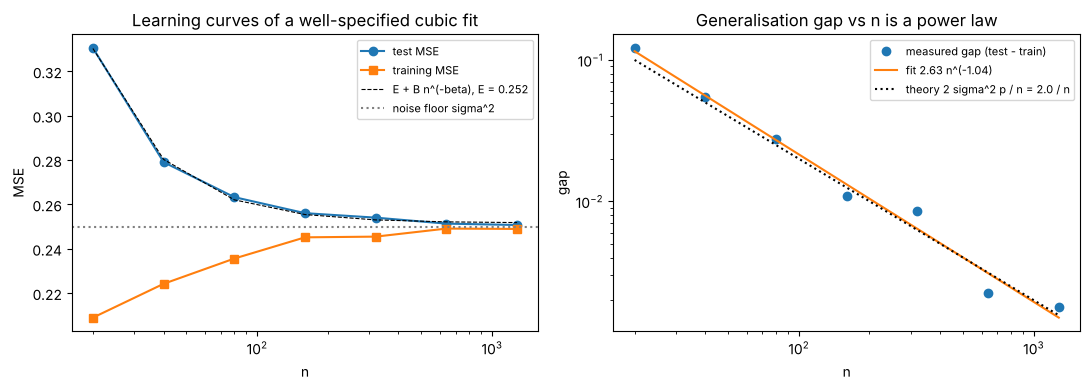

In [19]:
# ---- setting: cubic target, polynomial regression of the correct degree, noise sigma = 0.5 ----
g = np.random.default_rng(0)
coef_true = np.array([2.0, 0.0, -1.0, 0.5])        # highest power first (np.polyval convention): 2x^3 - x + 0.5
f_true = lambda x: np.polyval(coef_true, x)
sigma, degree = 0.5, 3
ns = np.array([20, 40, 80, 160, 320, 640, 1280])
n_reps, n_test = 200, 2000
print("number of parameters p =", degree + 1, "; noise variance sigma^2 =", sigma ** 2)


from scipy.optimize import curve_fit

train_mse = np.zeros(len(ns)); test_mse = np.zeros(len(ns)); gap = np.zeros(len(ns))
for i, n in enumerate(ns):
    tr, te = [], []
    for _ in range(n_reps):
        x = g.uniform(-1, 1, n); y = f_true(x) + sigma * g.normal(size=n)
        c = np.polyfit(x, y, degree)
        x_test = g.uniform(-1, 1, n_test); y_test = f_true(x_test) + sigma * g.normal(size=n_test)
        tr.append(np.mean((np.polyval(c, x) - y) ** 2))
        te.append(np.mean((np.polyval(c, x_test) - y_test) ** 2))
    train_mse[i], test_mse[i] = np.mean(tr), np.mean(te)
    gap[i] = test_mse[i] - train_mse[i]

slope, intercept = np.polyfit(np.log(ns), np.log(gap), 1)
gamma_fit, c_fit = -slope, np.exp(intercept)
p = degree + 1
print(f"{'n':>6s} {'train MSE':>10s} {'test MSE':>10s} {'gap':>8s} {'theory 2 sigma^2 p/n':>22s}")
for n, a, b, gp in zip(ns, train_mse, test_mse, gap):
    print(f"{n:6d} {a:10.4f} {b:10.4f} {gp:8.4f} {2 * sigma**2 * p / n:22.4f}")
print(f"\nfitted power law: gap ~ {c_fit:.2f} * n^(-{gamma_fit:.2f})     theory: {2*sigma**2*p:.2f} * n^(-1)")

law = lambda n, E, B, beta: E + B * n ** (-beta)
(E_fit, B_fit, beta_fit), _ = curve_fit(law, ns, test_mse, p0=[0.25, 2.0, 1.0], maxfev=20000)
print(f"scaling-law fit of the test MSE: E = {E_fit:.4f} (sigma^2 = {sigma**2}), B = {B_fit:.2f}, beta = {beta_fit:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].semilogx(ns, test_mse, "o-", label="test MSE")
axes[0].semilogx(ns, train_mse, "s-", label="training MSE")
axes[0].semilogx(ns, law(ns, E_fit, B_fit, beta_fit), "k--", lw=0.8, label=f"E + B n^(-beta), E = {E_fit:.3f}")
axes[0].axhline(sigma ** 2, color="gray", ls=":", label="noise floor sigma^2")
axes[0].set_title("Learning curves of a well-specified cubic fit"); axes[0].set_xlabel("n"); axes[0].set_ylabel("MSE"); axes[0].legend(fontsize=8)
axes[1].loglog(ns, gap, "o", label="measured gap (test - train)")
axes[1].loglog(ns, c_fit * ns ** (-gamma_fit), "-", label=f"fit {c_fit:.2f} n^(-{gamma_fit:.2f})")
axes[1].loglog(ns, 2 * sigma ** 2 * p / ns, "k:", label=f"theory 2 sigma^2 p / n = {2*sigma**2*p:.1f} / n")
axes[1].set_title("Generalisation gap vs n is a power law"); axes[1].set_xlabel("n"); axes[1].set_ylabel("gap"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Score

In [20]:
summary()


Score: 39/39 checks passed  🎉
